# Classical Models WITHOUT Encoder - Training Notebook

This notebook demonstrates training classical models (ShallowCNN and ResNet18) without encoder preprocessing.

**Model Variants:**
- `ShallowCNN`: 3-layer CNN processing raw images directly
- `ClassicalModel`: ResNet18-based model with transfer learning

These models learn features from scratch without pre-trained encoder.

## 1. Setup and Imports

In [48]:
import os
import sys
import torch
import torch.nn as nn
import torch.optim as optim
from datetime import datetime

# Add project root to path
project_root = '/home/eflammere/HybridEmbeddingsForBreastCancerDetection'
if project_root not in sys.path:
    sys.path.insert(0, project_root)

from src.utils.common import setup_device, setup_directories
from src.utils.dataloader import BreastMNISTLoader, BCDRLoader, INbreastLoader, BUSUCLMLoader
from src.utils.training import training_loop, test_model
from src.models.main.classical import ClassicalModel, ShallowCNN

print("✓ Imports successful")

✓ Imports successful


## 2. Configuration

In [49]:
# Training Configuration
CONFIG = {
    # Model settings
    'model_type': 'resnet',  # 'shallow' or 'resnet'
    'num_classes': 2,
    'input_channels': 1,  # 1 for grayscale, 3 for RGB
    
    # Dataset settings
    'dataset': 'busuclm',  # 'breastmnist', 'bcdr', 'inbreast', or 'busuclm'
    'batch_size': 16,
    'image_size': 28,
    
    # Training settings
    'epochs': 100,
    'learning_rate': 1e-3,
}

print("Configuration:")
for key, value in CONFIG.items():
    print(f"  {key}: {value}")

Configuration:
  model_type: resnet
  num_classes: 2
  input_channels: 1
  dataset: busuclm
  batch_size: 16
  image_size: 28
  epochs: 100
  learning_rate: 0.001


## 3. Setup Device and Directories

In [50]:
device = setup_device()
dirs = setup_directories()

# Create save directory
dataset_mapping = {
    'breastmnist': 'BreastMNIST',
    'bcdr': 'BCDR',
    'inbreast': 'INbreast',
    'busuclm': 'BUSUCLM'
}
dataset_name = dataset_mapping.get(CONFIG['dataset'], 'BreastMNIST')
model_type = CONFIG['model_type']
save_dir = os.path.join(
    dirs.get("project_dir", "."),
    "experiments", "models", dataset_name, "classical", model_type
)
os.makedirs(save_dir, exist_ok=True)

print(f"Device: {device}")
print(f"Save directory: {save_dir}")

Using: NVIDIA GeForce RTX 4070 Ti SUPER
CUDA: 12.4
Device: cuda
Save directory: ./experiments/models/BUSUCLM/classical/resnet


## 4. Load Dataset

In [51]:
if CONFIG['dataset'] == 'bcdr':
    loader = BCDRLoader(
        batch_size=CONFIG['batch_size'],
        image_size=CONFIG['image_size'],
        root_dir='src/data/BCDR/png'
    )
    print(f"✓ BCDR dataset loaded")
elif CONFIG['dataset'] == 'inbreast':
    loader = INbreastLoader(
        batch_size=CONFIG['batch_size'],
        image_size=CONFIG['image_size'],
        root_dir='src/data/INbreast/png'
    )
    print(f"✓ INbreast dataset loaded")
elif CONFIG['dataset'] == 'busuclm':
    loader = BUSUCLMLoader(
        batch_size=CONFIG['batch_size'],
        image_size=CONFIG['image_size'],
        root_dir='src/data/BUS-UCLM/png'
    )
    print(f"✓ BUSUCLM dataset loaded")
else:
    loader = BreastMNISTLoader(
        batch_size=CONFIG['batch_size'],
        image_size=CONFIG['image_size'],
    )
    print(f"✓ BreastMNIST dataset loaded")

train_loader, test_loader, val_loader = loader.get_dataloaders()

print(f"  Training batches: {len(train_loader)}")
print(f"  Validation batches: {len(val_loader)}")
print(f"  Test batches: {len(test_loader)}")

✓ BUSUCLM dataset loaded
Loaded 165 images from src/data/BUS-UCLM/png/train/0
Loaded 45 images from src/data/BUS-UCLM/png/train/1
Loaded 2 images from src/data/BUS-UCLM/png/val/0
Loaded 26 images from src/data/BUS-UCLM/png/val/1
Loaded 7 images from src/data/BUS-UCLM/png/test/0
Loaded 19 images from src/data/BUS-UCLM/png/test/1
  Training batches: 14
  Validation batches: 2
  Test batches: 2


## 5. Create Model WITHOUT Encoder

In [52]:
if CONFIG['model_type'] == 'shallow':
    model = ShallowCNN(
        num_classes=CONFIG['num_classes'],
        input_channels=CONFIG['input_channels']
    ).to(device)
    model_name = 'shallow_no_encoder'
else:
    model = ClassicalModel(
        num_classes=CONFIG['num_classes']
    ).to(device)
    model_name = 'resnet'

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print(f"✓ Model created: {model.__class__.__name__}")
print(f"  Total parameters: {total_params:,}")
print(f"  Trainable parameters: {trainable_params:,}")
print(f"  All parameters are trainable (no frozen encoder)")

✓ Model created: ClassicalModel
  Total parameters: 11,171,266
  Trainable parameters: 11,171,266
  All parameters are trainable (no frozen encoder)


## 6. Setup Training

In [53]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=CONFIG['learning_rate'])

print(f"✓ Training setup complete")
print(f"  Loss: CrossEntropyLoss")
print(f"  Optimizer: Adam (lr={CONFIG['learning_rate']})")
print(f"  Epochs: {CONFIG['epochs']}")

✓ Training setup complete
  Loss: CrossEntropyLoss
  Optimizer: Adam (lr=0.001)
  Epochs: 100


## 7. Train Model

In [54]:
print(f"\n{'='*80}")
print(f"Starting Training - {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}")
print(f"{'='*80}\n")

history = training_loop(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion,
    optimizer=optimizer,
    device=device,
    num_epochs=CONFIG['epochs'],
    save_dir=save_dir,
    model_name=model_name,
    extract_features=False,
    save_best_only=True,
    save_all_epochs=False
)

print(f"\n{'='*80}")
print(f"Training Complete - {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}")
print(f"{'='*80}")


Starting Training - 2026-02-11 09:47:46

Epoch 1/100



Epoch 1 Summary:
  Train - Loss: 0.9266, Acc: 0.6619
  Val   - Loss: 0.2114, Acc: 0.9286, Precision: 0.9286, Recall: 1.0000, F1: 0.9630, AUC: 0.5962
  ✓ New best model saved (val_acc: 0.9286) at ./experiments/models/BUSUCLM/classical/resnet/best_resnet.pth
Epoch 2/100



Epoch 2 Summary:
  Train - Loss: 0.8912, Acc: 0.6048
  Val   - Loss: 0.4907, Acc: 0.9286, Precision: 0.9286, Recall: 1.0000, F1: 0.9630, AUC: 0.6538
Epoch 3/100



Epoch 3 Summary:
  Train - Loss: 0.6656, Acc: 0.6333
  Val   - Loss: 0.5952, Acc: 0.7143, Precision: 0.9091, Recall: 0.7692, F1: 0.8333, AUC: 0.3846
Epoch 4/100



Epoch 4 Summary:
  Train - Loss: 0.5272, Acc: 0.7333
  Val   - Loss: 0.6542, Acc: 0.5357, Precision: 0.9333, Recall: 0.5385, F1: 0.6829, AUC: 0.6731
Epoch 5/100


...


Epoch 96 Summary:
  Train - Loss: 0.3009, Acc: 0.8952
  Val   - Loss: 1.7569, Acc: 0.5000, Precision: 1.0000, Recall: 0.4615, F1: 0.6316, AUC: 0.5385
Epoch 97/100



Epoch 97 Summary:
  Train - Loss: 0.1652, Acc: 0.9571
  Val   - Loss: 2.0406, Acc: 0.3929, Precision: 0.9091, Recall: 0.3846, F1: 0.5405, AUC: 0.4038
Epoch 98/100



Epoch 98 Summary:
  Train - Loss: 0.1111, Acc: 0.9619
  Val   - Loss: 1.9929, Acc: 0.4643, Precision: 1.0000, Recall: 0.4231, F1: 0.5946, AUC: 0.5000
Epoch 99/100



Epoch 99 Summary:
  Train - Loss: 0.2051, Acc: 0.9238
  Val   - Loss: 3.5572, Acc: 0.3214, Precision: 1.0000, Recall: 0.2692, F1: 0.4242, AUC: 0.2692
Epoch 100/100



Epoch 100 Summary:
  Train - Loss: 0.2402, Acc: 0.9476
  Val   - Loss: 1.6981, Acc: 0.4643, Precision: 0.9231, Recall: 0.4615, F1: 0.6154, AUC: 0.4615

Training Complete - 2026-02-11 09:53:12


## 8. Plot Training History

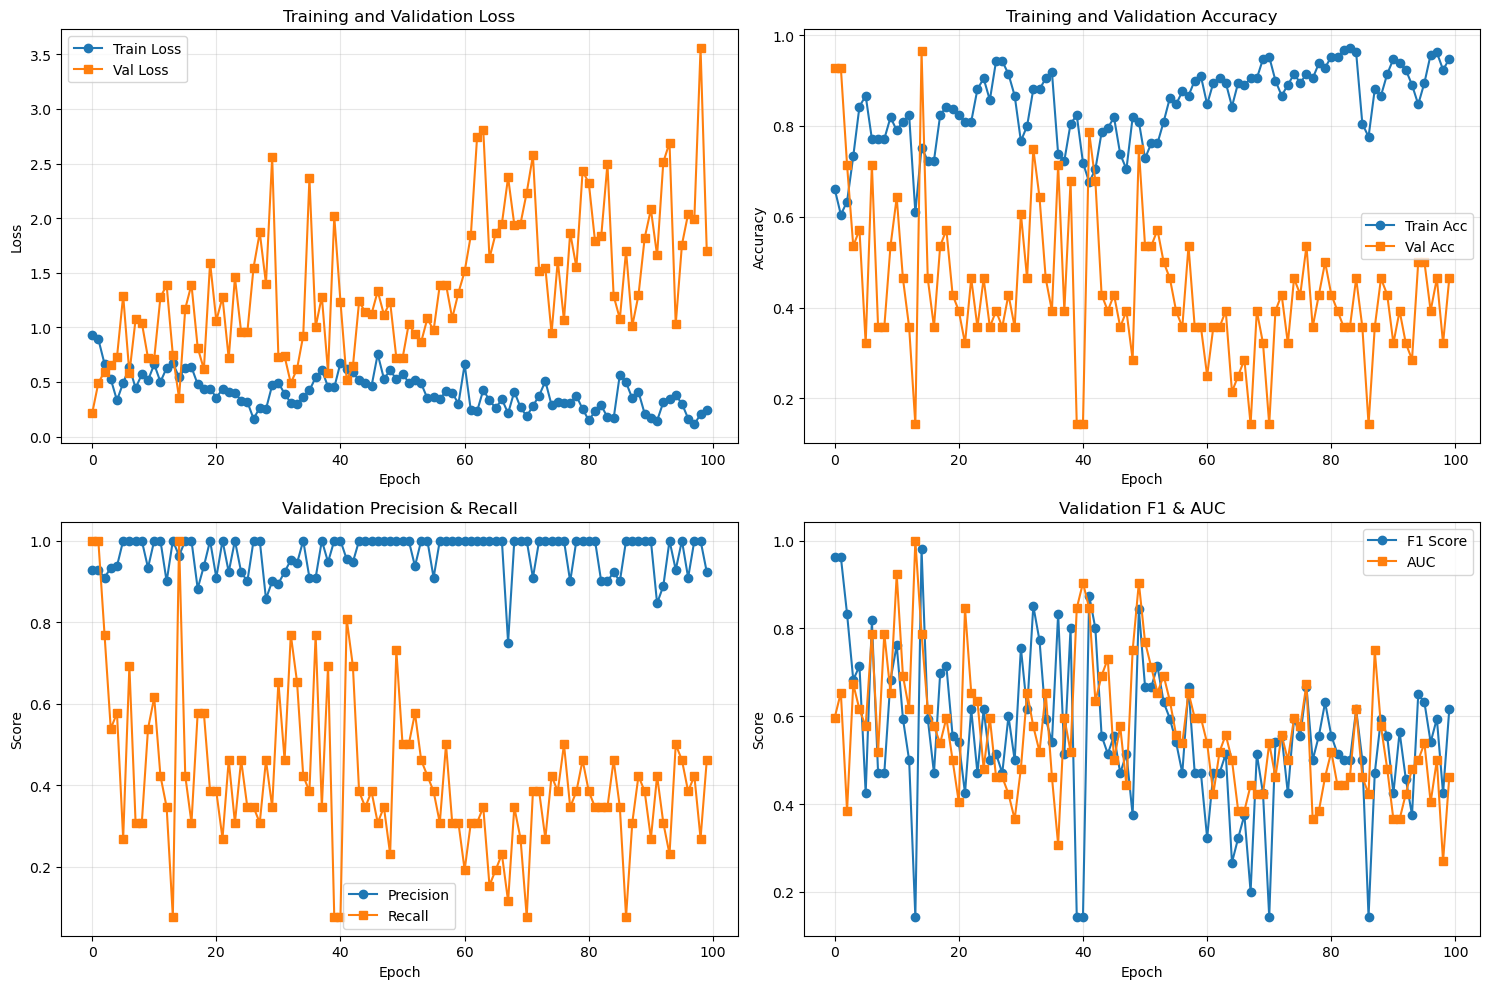

✓ Training curves saved to ./experiments/models/BUSUCLM/classical/resnet/training_history.png


In [55]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# Loss
axes[0, 0].plot(history['train_loss'], label='Train Loss', marker='o')
axes[0, 0].plot(history['val_loss'], label='Val Loss', marker='s')
axes[0, 0].set_xlabel('Epoch')
axes[0, 0].set_ylabel('Loss')
axes[0, 0].set_title('Training and Validation Loss')
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3)

# Accuracy
axes[0, 1].plot(history['train_acc'], label='Train Acc', marker='o')
axes[0, 1].plot(history['val_acc'], label='Val Acc', marker='s')
axes[0, 1].set_xlabel('Epoch')
axes[0, 1].set_ylabel('Accuracy')
axes[0, 1].set_title('Training and Validation Accuracy')
axes[0, 1].legend()
axes[0, 1].grid(True, alpha=0.3)

# Precision & Recall
axes[1, 0].plot(history['val_precision'], label='Precision', marker='o')
axes[1, 0].plot(history['val_recall'], label='Recall', marker='s')
axes[1, 0].set_xlabel('Epoch')
axes[1, 0].set_ylabel('Score')
axes[1, 0].set_title('Validation Precision & Recall')
axes[1, 0].legend()
axes[1, 0].grid(True, alpha=0.3)

# F1 & AUC
axes[1, 1].plot(history['val_f1'], label='F1 Score', marker='o')
axes[1, 1].plot(history['val_auc'], label='AUC', marker='s')
axes[1, 1].set_xlabel('Epoch')
axes[1, 1].set_ylabel('Score')
axes[1, 1].set_title('Validation F1 & AUC')
axes[1, 1].legend()
axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(save_dir, 'training_history.png'), dpi=150, bbox_inches='tight')
plt.show()

print(f"✓ Training curves saved to {save_dir}/training_history.png")

## 9. Load Best Model and Test

In [56]:
# Load best model
model_path = os.path.join(save_dir, f"best_{model_name}.pth")

if os.path.isfile(model_path):
    state = torch.load(model_path, map_location=device)
    model.load_state_dict(state)
    print(f"✓ Loaded best model from {model_path}")
else:
    print("⚠ Warning: No best model found, using final epoch weights")

model.eval()

✓ Loaded best model from ./experiments/models/BUSUCLM/classical/resnet/best_resnet.pth


/tmp/ipykernel_2070/524847859.py:5: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  state = torch.load(model_path, map_location=device)


ClassicalModel(
  (resnet): ResNet(
    (conv1): Conv2d(1, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
    (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (relu): ReLU(inplace=True)
    (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
    (layer1): Sequential(
      (0): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (relu): ReLU(inplace=True)
        (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      )
      (1): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, tra

In [57]:
# Test the model
print(f"\n{'='*80}")
print("Testing Best Model")
print(f"{'='*80}\n")

test_result = test_model(
    model=model,
    dataloader=test_loader,
    criterion=criterion,
    device=device,
    hyperparams=CONFIG
)

# Unpack the tuple (loss, accuracy, precision, recall, f1, auc)
test_loss, test_acc, test_prec, test_rec, test_f1, test_auc = test_result

# Create metrics dictionary for easier access
test_metrics = {
    'loss': float(test_loss),
    'accuracy': float(test_acc),
    'precision': float(test_prec),
    'recall': float(test_rec),
    'f1': float(test_f1),
    'auc': float(test_auc)
}

print("\nTest Results:")
print(f"  Loss: {test_metrics['loss']:.4f}")
print(f"  Accuracy: {test_metrics['accuracy']:.4f}")
print(f"  Precision: {test_metrics['precision']:.4f}")
print(f"  Recall: {test_metrics['recall']:.4f}")
print(f"  F1 Score: {test_metrics['f1']:.4f}")
print(f"  AUC: {test_metrics['auc']:.4f}")


Testing Best Model



Testing: 100%|██████████| 2/2 [00:00<00:00,  7.95it/s]

Test Loss: 0.4694
Accuracy: 0.8462, Precision: 0.8571, Recall: 0.9474, F1: 0.9000, AUC: 0.9098
Macro - Precision: 0.8286, Recall: 0.7594, F1: 0.7833
Micro - Precision: 0.8462, Recall: 0.8462, F1: 0.8462

Test Results:
  Loss: 0.4694
  Accuracy: 0.8462
  Precision: 0.8571
  Recall: 0.9474
  F1 Score: 0.9000
  AUC: 0.9098


In [58]:
# Save test results to text file
results_file = os.path.join(save_dir, f'test_results_{model_name}.txt')

with open(results_file, 'w', encoding='utf-8') as f:
    f.write("="*80 + "\n")
    f.write(f"TEST RESULTS - Classical Model WITHOUT Encoder\n")
    f.write("="*80 + "\n\n")
    
    f.write(f"Timestamp: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}\n\n")
    
    f.write("MODEL CONFIGURATION\n")
    f.write("-"*80 + "\n")
    f.write(f"Model Type: {model.__class__.__name__}\n")
    f.write(f"Model Variant: {CONFIG['model_type']}\n")
    f.write(f"Dataset: {CONFIG['dataset'].upper()}\n")
    f.write(f"Encoder: None (end-to-end training)\n")
    f.write(f"Total Parameters: {total_params:,}\n")
    f.write(f"Trainable Parameters: {trainable_params:,}\n\n")
    
    f.write("TRAINING HYPERPARAMETERS\n")
    f.write("-"*80 + "\n")
    f.write(f"Epochs: {CONFIG['epochs']}\n")
    f.write(f"Batch Size: {CONFIG['batch_size']}\n")
    f.write(f"Learning Rate: {CONFIG['learning_rate']}\n")
    f.write(f"Image Size: {CONFIG['image_size']}\n")
    f.write(f"Input Channels: {CONFIG['input_channels']}\n")
    f.write(f"Number of Classes: {CONFIG['num_classes']}\n\n")
    
    f.write("BEST VALIDATION METRICS\n")
    f.write("-"*80 + "\n")
    f.write(f"Best Validation Accuracy: {max(history['val_acc']):.4f}\n")
    f.write(f"Best Validation F1 Score: {max(history['val_f1']):.4f}\n")
    f.write(f"Best Validation AUC: {max(history['val_auc']):.4f}\n")
    f.write(f"Best Validation Precision: {max(history['val_precision']):.4f}\n")
    f.write(f"Best Validation Recall: {max(history['val_recall']):.4f}\n\n")
    
    f.write("FINAL TEST METRICS\n")
    f.write("-"*80 + "\n")
    f.write(f"Test Loss: {test_metrics['loss']:.4f}\n")
    f.write(f"Test Accuracy: {test_metrics['accuracy']:.4f}\n")
    f.write(f"Test Precision: {test_metrics['precision']:.4f}\n")
    f.write(f"Test Recall: {test_metrics['recall']:.4f}\n")
    f.write(f"Test F1 Score: {test_metrics['f1']:.4f}\n")
    f.write(f"Test AUC: {test_metrics['auc']:.4f}\n\n")
    
    if 'macro_precision' in test_metrics:
        f.write("MACRO-AVERAGED METRICS\n")
        f.write("-"*80 + "\n")
        f.write(f"Macro Precision: {test_metrics['macro_precision']:.4f}\n")
        f.write(f"Macro Recall: {test_metrics['macro_recall']:.4f}\n")
        f.write(f"Macro F1 Score: {test_metrics['macro_f1']:.4f}\n\n")
    
    if 'micro_precision' in test_metrics:
        f.write("MICRO-AVERAGED METRICS\n")
        f.write("-"*80 + "\n")
        f.write(f"Micro Precision: {test_metrics['micro_precision']:.4f}\n")
        f.write(f"Micro Recall: {test_metrics['micro_recall']:.4f}\n")
        f.write(f"Micro F1 Score: {test_metrics['micro_f1']:.4f}\n\n")
    
    f.write("MODEL SAVE LOCATION\n")
    f.write("-"*80 + "\n")
    f.write(f"Directory: {save_dir}\n")
    f.write(f"Best Model: best_{model_name}.pth\n\n")
    
    f.write("="*80 + "\n")
    f.write("END OF REPORT\n")
    f.write("="*80 + "\n")

print(f"✓ Test results saved to: {results_file}")

✓ Test results saved to: ./experiments/models/BUSUCLM/classical/resnet/test_results_resnet.txt


## 10. Visualize Sample Predictions

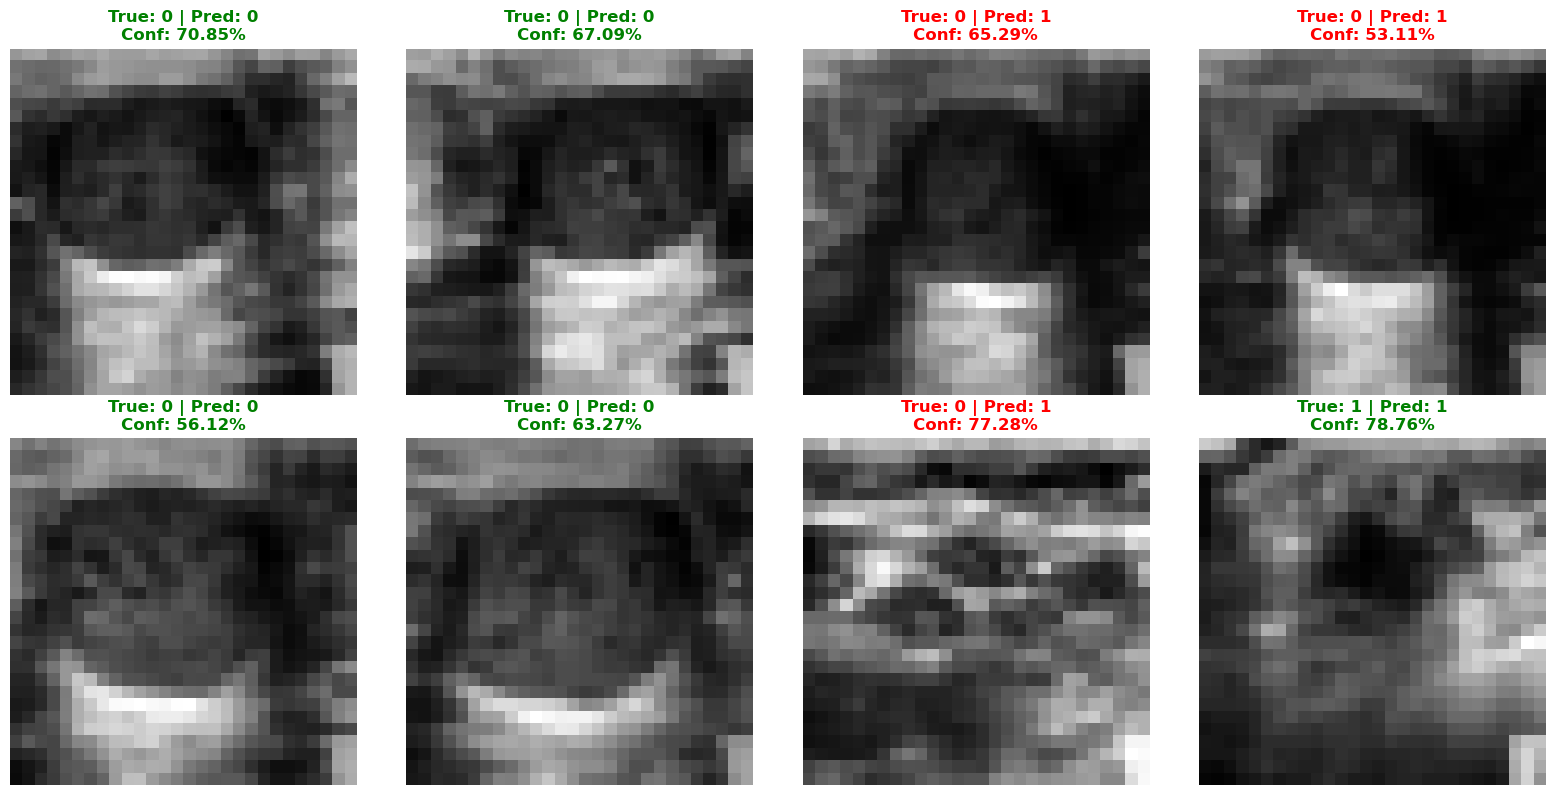

✓ Sample predictions saved to ./experiments/models/BUSUCLM/classical/resnet/sample_predictions.png


In [59]:
import numpy as np

# Get a batch of test images
dataiter = iter(test_loader)
images, labels = next(dataiter)
images, labels = images.to(device), labels.to(device)

# Make predictions
with torch.no_grad():
    outputs = model(images)
    _, predicted = torch.max(outputs, 1)
    probs = torch.softmax(outputs, dim=1)

# Visualize
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.ravel()

for idx in range(min(8, len(images))):
    img = images[idx].cpu().squeeze().numpy()
    true_label = labels[idx].cpu().item()
    pred_label = predicted[idx].cpu().item()
    confidence = probs[idx][pred_label].cpu().item()
    
    axes[idx].imshow(img, cmap='gray')
    axes[idx].axis('off')
    
    color = 'green' if true_label == pred_label else 'red'
    title = f"True: {true_label} | Pred: {pred_label}\nConf: {confidence:.2%}"
    axes[idx].set_title(title, color=color, fontweight='bold')

plt.tight_layout()
plt.savefig(os.path.join(save_dir, 'sample_predictions.png'), dpi=150, bbox_inches='tight')
plt.show()

print(f"✓ Sample predictions saved to {save_dir}/sample_predictions.png")

## 11. Summary

In [60]:
print("\n" + "="*80)
print("TRAINING SUMMARY - Classical Model WITHOUT Encoder")
print("="*80)
print(f"\nModel: {model.__class__.__name__}")
print(f"Dataset: {CONFIG['dataset'].upper()}")
print(f"Encoder: None (end-to-end training)")
print(f"\nArchitecture:")
print(f"  Total parameters: {total_params:,}")
print(f"  Trainable parameters: {trainable_params:,}")
print(f"\nBest Validation Results:")
print(f"  Accuracy: {max(history['val_acc']):.4f}")
print(f"  F1 Score: {max(history['val_f1']):.4f}")
print(f"  AUC: {max(history['val_auc']):.4f}")
print(f"\nFinal Test Results:")
print(f"  Accuracy: {test_metrics['accuracy']:.4f}")
print(f"  F1 Score: {test_metrics['f1']:.4f}")
print(f"  AUC: {test_metrics['auc']:.4f}")
print(f"\nModel saved at: {save_dir}")
print("="*80)


TRAINING SUMMARY - Classical Model WITHOUT Encoder

Model: ClassicalModel
Dataset: BUSUCLM
Encoder: None (end-to-end training)

Architecture:
  Total parameters: 11,171,266
  Trainable parameters: 11,171,266

Best Validation Results:
  Accuracy: 0.9643
  F1 Score: 0.9811
  AUC: 1.0000

Final Test Results:
  Accuracy: 0.8462
  F1 Score: 0.9000
  AUC: 0.9098

Model saved at: ./experiments/models/BUSUCLM/classical/resnet
